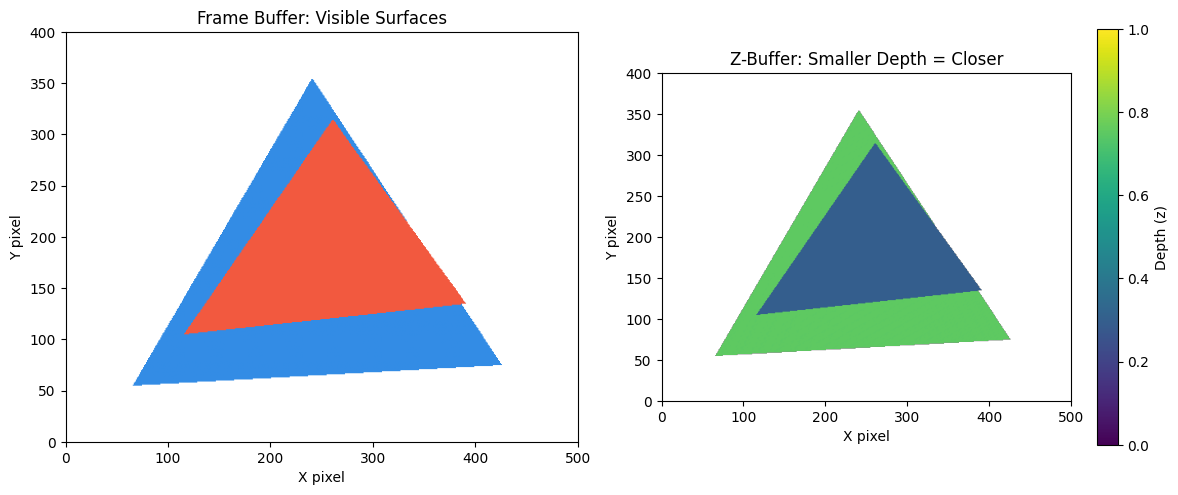

Z-Buffer algorithm executed successfully.
At each pixel, the color is updated only when the new depth is smaller.


In [1]:
# Experiment 6: Z-Buffer Algorithm for Hidden Surface Removal
# Run this cell to visualize depth-buffer-based hidden surface removal.

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Frame-buffer and depth-buffer dimensions
WIDTH, HEIGHT = 500, 400
background_color = np.array([1.0, 1.0, 1.0])
frame_buffer = np.ones((HEIGHT, WIDTH, 3), dtype=float) * background_color
z_buffer = np.full((HEIGHT, WIDTH), np.inf, dtype=float)

def edge_function(a, b, x, y):
    return (x - a[0]) * (b[1] - a[1]) - (y - a[1]) * (b[0] - a[0])

def rasterize_triangle(vertices, depth_values, color):
    """Rasterize a triangle and keep the closest fragment at each pixel."""
    vertices = np.asarray(vertices, dtype=float)
    depth_values = np.asarray(depth_values, dtype=float)
    min_x = max(0, int(np.floor(vertices[:, 0].min())))
    max_x = min(WIDTH - 1, int(np.ceil(vertices[:, 0].max())))
    min_y = max(0, int(np.floor(vertices[:, 1].min())))
    max_y = min(HEIGHT - 1, int(np.ceil(vertices[:, 1].max())))

    if min_x > max_x or min_y > max_y:
        return

    a, b, c = vertices
    area = edge_function(a, b, c[0], c[1])
    if abs(area) < 1e-9:
        return

    for py in range(min_y, max_y + 1):
        for px in range(min_x, max_x + 1):
            x, y = px + 0.5, py + 0.5
            w0 = edge_function(b, c, x, y) / area
            w1 = edge_function(c, a, x, y) / area
            w2 = edge_function(a, b, x, y) / area

            if w0 >= -1e-9 and w1 >= -1e-9 and w2 >= -1e-9:
                depth = w0 * depth_values[0] + w1 * depth_values[1] + w2 * depth_values[2]
                if depth < z_buffer[py, px]:
                    z_buffer[py, px] = depth
                    frame_buffer[py, px] = color

# Overlapping triangles: the farther triangle is drawn first on purpose.
triangles = [
    {
        "vertices": [(65, 55), (425, 75), (240, 355)],
        "depths": [0.75, 0.75, 0.75],
        "color": (0.20, 0.55, 0.90),
        "name": "Far triangle"
    },
    {
        "vertices": [(115, 105), (390, 135), (260, 315)],
        "depths": [0.30, 0.30, 0.30],
        "color": (0.95, 0.35, 0.25),
        "name": "Near triangle"
    }
]

for triangle in triangles:
    rasterize_triangle(
        triangle["vertices"],
        triangle["depths"],
        triangle["color"]
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].imshow(frame_buffer, origin="lower", extent=[0, WIDTH, 0, HEIGHT])
axes[0].set_title("Frame Buffer: Visible Surfaces")
axes[0].set_xlabel("X pixel")
axes[0].set_ylabel("Y pixel")
axes[0].set_xlim(0, WIDTH)
axes[0].set_ylim(0, HEIGHT)

depth_display = np.ma.masked_invalid(np.where(np.isfinite(z_buffer), z_buffer, np.nan))
im = axes[1].imshow(
    depth_display, origin="lower", extent=[0, WIDTH, 0, HEIGHT],
    vmin=0, vmax=1, cmap="viridis"
)
axes[1].set_title("Z-Buffer: Smaller Depth = Closer")
axes[1].set_xlabel("X pixel")
axes[1].set_ylabel("Y pixel")
fig.colorbar(im, ax=axes[1], label="Depth (z)")
plt.tight_layout()
plt.show()

print("Z-Buffer algorithm executed successfully.")
print("At each pixel, the color is updated only when the new depth is smaller.")
